In [1]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

d:\Explainable-AI-CDSS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.52.0


In [2]:
X_test = pd.read_csv(
    "../datasets/processed/diabetes/x_test.csv"
)

y_test = pd.read_csv(
    "../datasets/processed/diabetes/y_test.csv"
).squeeze()

model = joblib.load(
    "../models/diabetes/best_model.pkl"
)

print("X_test shape:", X_test.shape)
print("Model:", model)

X_test shape: (104, 16)
Model: DecisionTreeClassifier(random_state=42)


In [3]:
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

print("SHAP values generated successfully.")

SHAP values generated successfully.


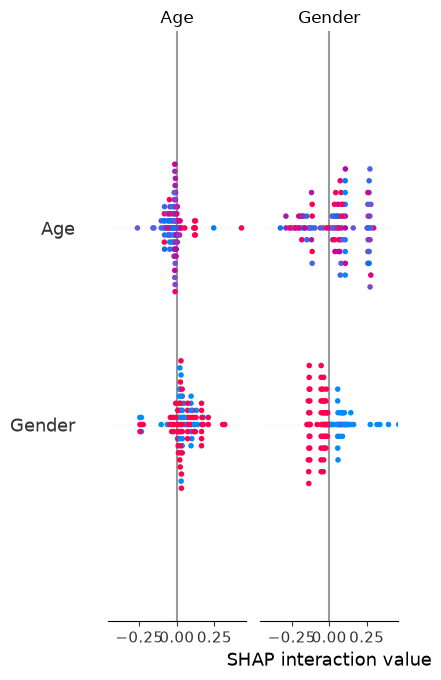

In [4]:
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns
)

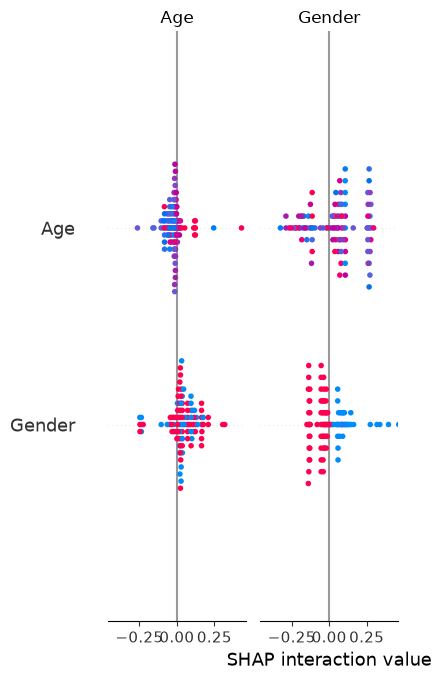

In [5]:
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns,
    plot_type="bar"
)

In [6]:
print("SHAP values type:", type(shap_values))
print("SHAP values shape:", np.array(shap_values).shape)

SHAP values type: <class 'numpy.ndarray'>
SHAP values shape: (104, 16, 2)


In [7]:
patient_index = 0

patient = X_test.iloc[[patient_index]]

print("Patient features:")
display(patient)

Patient features:


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity
0,0.167953,-1.304338,-0.99043,-0.886232,-0.860573,0.818952,-0.92582,-0.544013,1.101257,1.029274,-0.540301,1.064581,-0.873334,-0.770629,1.404076,-0.461333


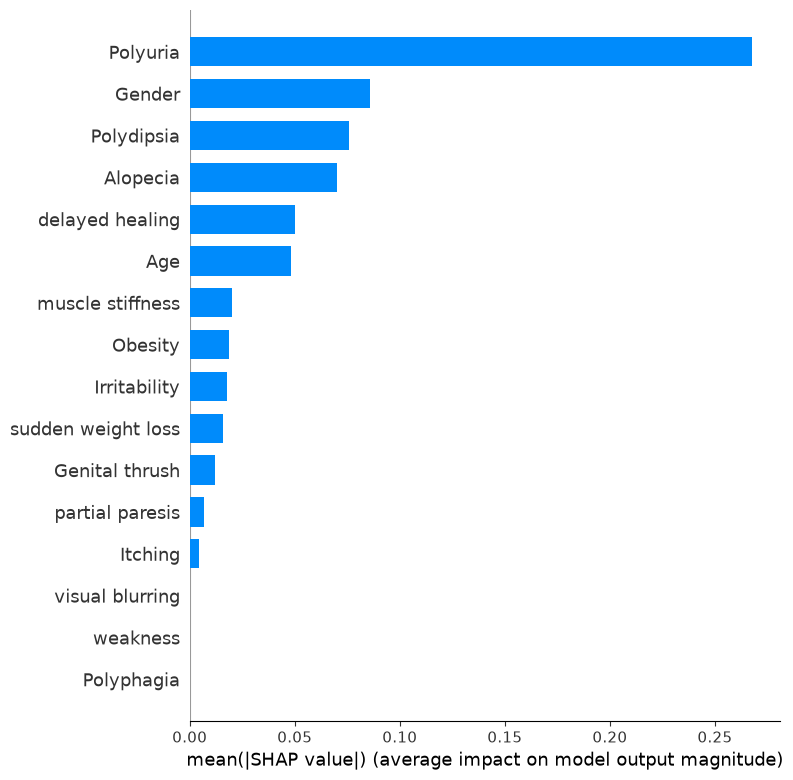

In [15]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test,
    feature_names=X_test.columns,
    plot_type="bar"
)

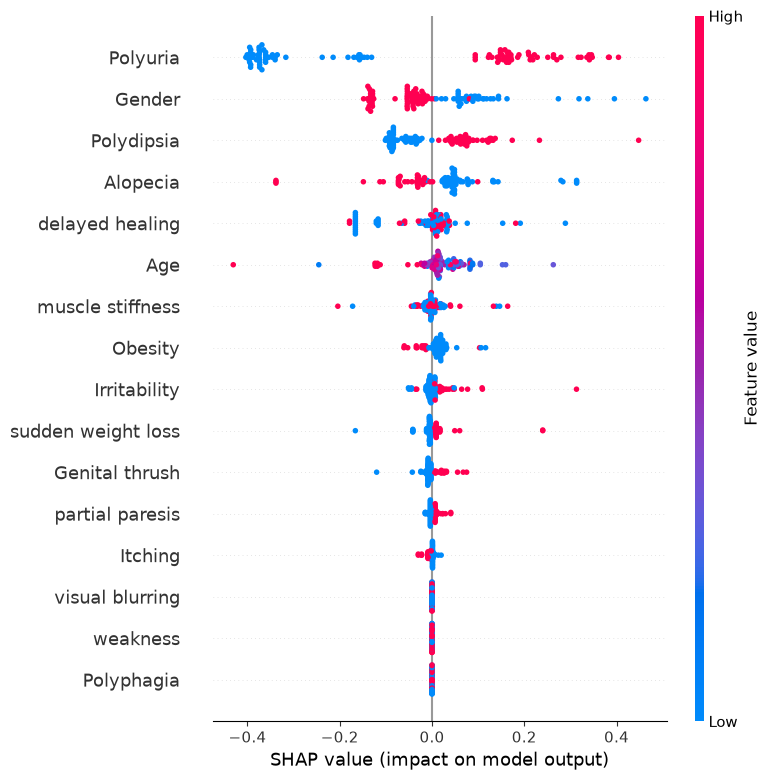

In [16]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test,
    feature_names=X_test.columns
)

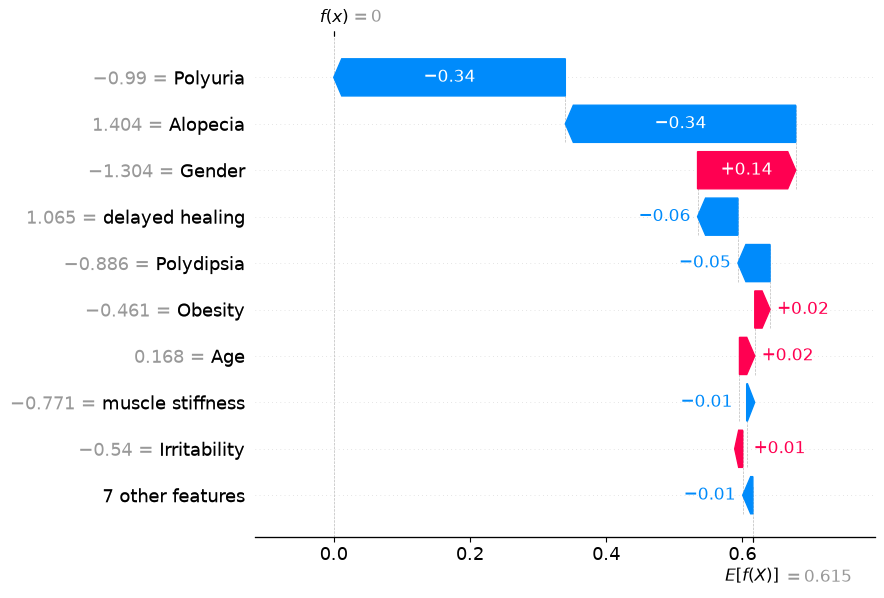

In [10]:
# Explain the first patient for the positive diabetes class

shap.plots.waterfall(patient_shap[0, :, 1])

Selected SHAP explanation shape: (16,)


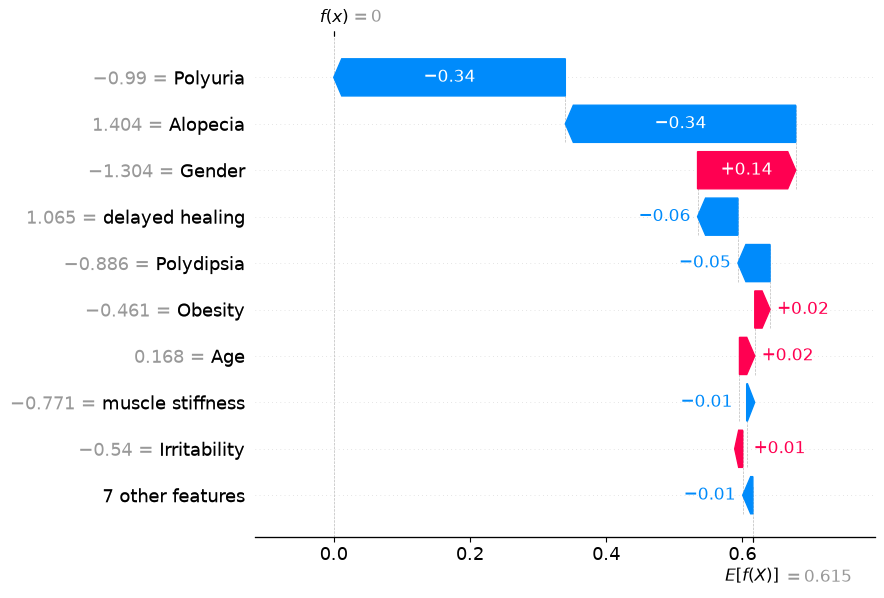

In [13]:
# Select the first patient and Positive (class 1) explanation
single_patient_shap = patient_shap[0, :, 1]

print("Selected SHAP explanation shape:", single_patient_shap.values.shape)

shap.plots.waterfall(single_patient_shap)

In [11]:
print("Patient SHAP shape:", patient_shap.values.shape)
print("Base values shape:", np.array(patient_shap.base_values).shape)

Patient SHAP shape: (1, 16, 2)
Base values shape: (1, 2)


In [14]:
patient_shap[0, :, 1]


.values =
array([ 0.02246169,  0.14413528, -0.34004603, -0.04722816, -0.00554734,
        0.        ,  0.        , -0.00496433,  0.        , -0.00164214,
        0.00587976, -0.05924109, -0.00281244, -0.01059636, -0.33825526,
        0.0224718 ])

.base_values =
np.float64(0.6153846153846154)

.data =
array([ 0.16795255, -1.30433842, -0.9904304 , -0.88623232, -0.86057293,
        0.81895222, -0.9258201 , -0.54401301,  1.10125654,  1.02927447,
       -0.54030127,  1.06458129, -0.87333376, -0.77062944,  1.4040757 ,
       -0.46133284])